# Displacements and topology changes

*Experimental: a proof of concept.*

`px.DeformableShape(face, h, min_distance)` represents a face as dense closed polylines. Every edge is sampled at most
`h` apart, outer loops run counterclockwise and holes clockwise. `SetDeformation(d)` moves every vertex by its row of
the array `d`, which has one row of two displacements per vertex. When parts of the boundary come closer than
`min_distance`, the shape changes its topology: a hole opens to the outside, and parts merge or split.
`SetDeformation` returns `True` when this happens.

The example is a square plate 2 × 2 with a hole of radius 0.4. The edges are sampled 0.05 apart, and parts of the
boundary may come as close as 0.1 (Figure 1).

In [1]:
import numpy as np
import planex as px

face = px.QuickSketch().RectangleC(2, 2, name="outer").Circle(0, 0, 0.4, name="hole").Face()
shape = px.DeformableShape(face, h=0.05, min_distance=0.1)

In [2]:
from docs_figures import Row, Vertices

In [3]:
Row((shape, "A plate with a hole, as dense polylines"),
    caption="A deformable shape made from a face")

## Moving the hole up

Every vertex keeps the name of the edge it was sampled from, and `VertexNames()` lists these names in the order of
the vertices. The displacement therefore selects the hole by its name and moves it up by 0.02 per step, while the
outline stays in place. The loop stops at the first topology change (Figure 2).

In [4]:
for step in range(40):
    names = np.array(shape.VertexNames())
    d = np.zeros((len(shape), 2))
    d[names == "hole", 1] = 0.02
    if shape.SetDeformation(d):
        print("topology changed at step", step)
        break

topology changed at step 24


In [5]:
Row((shape, "The hole moved up until it opened"),
    caption="The hole has opened through the top of the outline")

## What happens at a topology change

The picture shows the top edge enlarged, in a run with smaller steps. The outline is black, the hole green and the
new edges red. At step 120, the top of the hole comes closer to the outline than `min_distance`. At step 121, the
vertices on both sides that are too close are removed, and the loose ends are joined by straight edges, so the hole
opens into a notch. As the hole keeps rising, every part of its arc that comes too close is cut away in the same way.
The new edges have no name, so in a simulation they form a free boundary.

![A hole opening through the outline, steps 120 to 150](topology_change.png)

## Results

The deformable shape measures its area like any other object. `RingSizes()` gives the number of vertices of each
loop, and `IsValid()` checks that the polylines cross neither themselves nor each other.

In [6]:
shape.mass, shape.RingSizes(), shape.IsValid()

(3.4986113525434224, [163, 54], True)

`Shape()` returns the current geometry as a planex2d shape, ready for the export to netgen and OpenCASCADE.

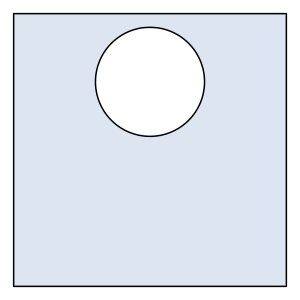

In [7]:
shape.Shape()